# Probing two pretrained models: tokeniser edge cases and next-token distributions

This notebook runs the same experiments on **two models at once**, one step at a time, so you can see the output of each idea before moving on and compare the models side by side.

1. **Tokeniser:** how does each model turn text into tokens, and where does that get strange? (whitespace, numbers, emoji, other languages, special-token strings, control characters)
2. **Next-token distribution:** given a prompt, what does each model think comes next, how sure is it, and how much does that change when the prompt changes slightly?


**Default models**
| model | why it is a useful pair |
|---|---|
| `gpt2` | 124M parameters, trained 2019, a 50k-token byte-level BPE vocabulary, mostly English |
| `Qwen/Qwen2.5-0.5B` | 0.5B parameters, trained 2024, a ~150k-token vocabulary with far more multilingual and code data |

## 0. Setup

In [5]:
# Google Colab already includes torch, pandas and matplotlib; only transformers needs to be present.
%pip install -q transformers

In [6]:
import math, os, unicodedata
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 300)

device = "cuda" if torch.cuda.is_available() else "cpu"
PALETTE = ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]   # one colour per model, used in every chart
print("device:", device)

device: cpu


In [7]:
HF_TOKEN = ""   # only needed for gated models

if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN") or ""
    except Exception:
        pass
HF_TOKEN = HF_TOKEN or os.environ.get("HF_TOKEN", "")

if HF_TOKEN:
    from huggingface_hub import login, whoami
    login(token=HF_TOKEN, add_to_git_credential=False)
    try:
        print("Logged in to Hugging Face as:", whoami()["name"])
    except Exception as e:
        print("Token set, but could not verify it:", type(e).__name__)
else:
    print("No token set. That is fine for public models such as gpt2 and Qwen/Qwen2.5-0.5B.")

No token set. That is fine for public models such as gpt2 and Qwen/Qwen2.5-0.5B.


### Load the models

In [8]:
MODELS = os.environ["MODELS"].split(",") if "MODELS" in os.environ else [
    "gpt2",
    "Qwen/Qwen2.5-0.5B",
]

LOADED = {}      # name -> {"tok":..., "model":..., "short":...}
for name in MODELS:
    try:
        t = AutoTokenizer.from_pretrained(name, token=HF_TOKEN or None)
        m = AutoModelForCausalLM.from_pretrained(name, token=HF_TOKEN or None).to(device).eval()
    except Exception as e:
        print(f"!! could not load {name}: {type(e).__name__}: {str(e)[:250]}\n")
        continue
    LOADED[name] = {"tok": t, "model": m, "short": name.rstrip("/").split("/")[-1]}

if not LOADED:
    raise RuntimeError("No model could be loaded. Check the names in MODELS (and the token for gated models).")

rows = []
for name, m in LOADED.items():
    rows.append({
        "model": m["short"],
        "parameters_M": round(sum(p.numel() for p in m["model"].parameters()) / 1e6, 1),
        "tokenizer_vocab": len(m["tok"]),
        "logit_dim": m["model"].get_output_embeddings().weight.shape[0],
        "bos": m["tok"].bos_token,
        "eos": m["tok"].eos_token,
        "unk": m["tok"].unk_token,
    })
pd.DataFrame(rows).set_index("model")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

... (9 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

,parameters_M,tokenizer_vocab,logit_dim,bos,eos,unk
model,,,,,,
gpt2,124.4,50257,50257,<|endoftext|>,<|endoftext|>,<|endoftext|>
Qwen2.5-0.5B,494.0,151665,151936,None,<|endoftext|>,None


# Part 1: Tokeniser edge cases

## 1.1 The basics: text in, integer ids out

A language model never sees text. It sees a list of integers. The tokeniser splits the text into **pieces** (sub-words, bytes, or whole words) and looks each one up in a fixed vocabulary.

Common words are usually a single token. Some pieces start with a special marker (for GPT-2 style tokenisers, `Ġ` means "this piece begins with a space"). The marker is how the tokeniser remembers where the spaces were.

In [9]:
text = "Hello, world! Tokenisation is fun."
for name, m in LOADED.items():
    tok = m["tok"]
    ids = tok.encode(text, add_special_tokens=False)
    print(f"=== {m['short']}")
    print("text   :", repr(text))
    print("ids    :", ids)
    print("pieces :", tok.convert_ids_to_tokens(ids))
    print("decoded:", repr(tok.decode(ids)))
    print(f"{len(text)} characters -> {len(ids)} tokens  ({len(text)/len(ids):.2f} chars per token)\n")

=== gpt2
text   : 'Hello, world! Tokenisation is fun.'
ids    : [15496, 11, 995, 0, 29130, 5612, 318, 1257, 13]
pieces : ['Hello', ',', 'Ġworld', '!', 'ĠToken', 'isation', 'Ġis', 'Ġfun', '.']
decoded: 'Hello, world! Tokenisation is fun.'
34 characters -> 9 tokens  (3.78 chars per token)

=== Qwen2.5-0.5B
text   : 'Hello, world! Tokenisation is fun.'
ids    : [9707, 11, 1879, 0, 9660, 7923, 374, 2464, 13]
pieces : ['Hello', ',', 'Ġworld', '!', 'ĠToken', 'isation', 'Ġis', 'Ġfun', '.']
decoded: 'Hello, world! Tokenisation is fun.'
34 characters -> 9 tokens  (3.78 chars per token)



#### **Takeaway.** For ordinary English the two tokenisers agree.

## 1.2 Helper function

For each test string we record: the pieces, the token count, **bytes per token** (higher means the tokeniser handles this kind of text efficiently), and whether **decoding the ids gives back exactly the original text** (a lossy round trip is a red flag).

Whitespace and control characters are made visible: `␣` is a space, `\n` a newline, and so on.

In [10]:
def visible(s):
    """Make whitespace / control characters readable."""
    out = []
    for ch in s:
        cat = unicodedata.category(ch)
        if ch == " ":
            out.append("␣")
        elif ch == "\n":
            out.append("\\n")
        elif ch == "\t":
            out.append("\\t")
        elif ch == "\r":
            out.append("\\r")
        elif cat.startswith("C") or cat == "Zs":
            out.append(f"\\u{ord(ch):04x}")
        else:
            out.append(ch)
    return "".join(out)


ALL_ROWS = []      # every tokeniser probe is stored here for the summary later


def probe_text(name, category, label, text):
    # Run ONE edge case through ONE model's tokeniser.
    tok = LOADED[name]["tok"]
    special_ids = set(tok.all_special_ids)
    unk_id = tok.unk_token_id
    ids = tok.encode(text, add_special_tokens=False)
    pieces = tok.convert_ids_to_tokens(ids) if ids else []
    decoded = tok.decode(ids, clean_up_tokenization_spaces=False) if ids else ""
    n_bytes = len(text.encode("utf-8"))
    return {
        "category": category,
        "case": label,
        "model": LOADED[name]["short"],
        "input": visible(text),
        "n_tokens": len(ids),
        "bytes/token": round(n_bytes / len(ids), 2) if ids else None,
        "round_trip": "ok" if decoded == text else "LOSSY",
        "decoded": visible(decoded),
        "has_unk": bool(unk_id is not None and unk_id not in (tok.bos_token_id, tok.eos_token_id) and unk_id in ids),
        "is_special": bool(special_ids & set(ids)),
        "pieces": " ".join(visible(p) for p in pieces),
    }


def run_cases(category, cases):
    # The nested loop: for each edge case, for each model. Rows for the same case sit together.
    rows = []
    for label, text in cases:              # each edge case ...
        for name in LOADED:                # ... through each model
            rows.append(probe_text(name, category, label, text))
    ALL_ROWS.extend(rows)
    return pd.DataFrame(rows).set_index(["case", "model"])[["input", "n_tokens", "bytes/token", "round_trip", "pieces"]]


print("Helpers ready: visible(), probe_text(), run_cases()   models:", [m["short"] for m in LOADED.values()])

Helpers ready: visible(), probe_text(), run_cases()   models: ['gpt2', 'Qwen2.5-0.5B']


### 📋 Report · 1.2 Helper functions

**What happened.** No experiment ran here. This cell defined the tools used in 1.3-1.9 and printed `Helpers ready`.

**What each tool does**
- `visible()` makes invisible characters readable (`␣` for a space, `\n` for a newline) so you can see what is really in each string.
- `probe_text()` runs one string through one tokeniser and records **n_tokens**, **bytes/token** (higher means more efficient; it uses bytes so that scripts with different character sizes are comparable), and **round_trip** (does decode(encode(text)) give back exactly the original? `LOSSY` means no).
- `run_cases()` loops over every test string and every model, so the two models' rows sit next to each other in the table.

**How to read every table from here on.** For each test string there are two rows (gpt2, then Qwen). Compare `n_tokens` (fewer = cheaper) and look at `pieces` to see *where* the text was cut.


## 1.3 Whitespace

Spaces, tabs and newlines are where tokenisers are most inconsistent. In many tokenisers `hello` and `␣hello` are **different tokens with different ids**, so the model treats a leading space as part of the word.

In [11]:
run_cases("whitespace", [
    ("empty string",              ""),
    ("single space",              " "),
    ("word, no space",            "hello"),
    ("word, leading space",       " hello"),
    ("word, two leading spaces",  "  hello"),
    ("word, trailing space",      "hello "),
    ("16 spaces",                 " " * 16),
    ("tab",                       "a\tb"),
    ("newline",                   "a\nb"),
    ("CRLF",                      "a\r\nb"),
    ("blank lines",               "a\n\n\nb"),
])

input  n_tokens  bytes/token round_trip                           pieces
case                     model                                                                                            
empty string             gpt2                                   0          NaN         ok                                 
                         Qwen2.5-0.5B                           0          NaN         ok                                 
single space             gpt2                         ␣         1         1.00         ok                                Ġ
                         Qwen2.5-0.5B                 ␣         1         1.00         ok                                Ġ
word, no space           gpt2                     hello         1         5.00         ok                            hello
                         Qwen2.5-0.5B             hello         1         5.00         ok                            hello
word, leading space      gpt2                    ␣hello         1         6.00         ok                           Ġhello
                         Qwen2.5-0.5B            ␣hello         1         6.00         ok                           Ġhello
word, two leading spaces gpt2                   ␣␣hello         2         3.50         ok                         Ġ Ġhello
                         Qwen2.5-0.5B           ␣␣hello         2         3.50         ok                         Ġ Ġhello
word, trailing space     gpt2                    hello␣         2         3.00         ok                          hello Ġ
                         Qwen2.5-0.5B            hello␣         2         3.00         ok                          hello Ġ
16 spaces                gpt2          ␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣        16         1.00         ok  Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ Ġ
                         Qwen2.5-0.5B  ␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣         1        16.00         ok                 ĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠ
tab                      gpt2                      a\tb         3         1.00         ok                            a ĉ b
                         Qwen2.5-0.5B              a\tb         2         1.50         ok                             a ĉb
newline                  gpt2                      a\nb         3         1.00         ok                            a Ċ b
                         Qwen2.5-0.5B              a\nb         3         1.00         ok                            a Ċ b
CRLF                     gpt2                    a\r\nb         4         1.00         ok                          a č Ċ b
                         Qwen2.5-0.5B            a\r\nb         3         1.33         ok                           a čĊ b
blank lines              gpt2                  a\n\n\nb         4         1.25         ok                         a ĊĊ Ċ b
                         Qwen2.5-0.5B          a\n\n\nb         3         1.67         ok                          a ĊĊĊ b

### **What the table shows**
- **A leading space is part of the token.** `hello` and `Ġhello` are different tokens (both cost 1).

- **Extra spaces become their own tokens.** Two leading spaces give `Ġ` + `Ġhello` (2 tokens). 

- A trailing space gives `hello` + `Ġ` (2 tokens), a lone space token.

- **The biggest difference: 16 spaces.** GPT-2 needs **16 tokens** (the same `Ġ` token 16 times). Qwen needs **1**. Qwen also merges newline and tab combinations: `a\n\n\nb` is 4 tokens in GPT-2 but 3 in Qwen (`ĊĊĊ` is one token), and CRLF and tab are also one token shorter.

- The empty string is 0 tokens (bytes/token shows `NaN` because it would divide by zero).

**Why it matters.** Indented code and structured text are full of runs of whitespace. GPT-2 wastes context on them; Qwen was built to compress them. 


## 1.4 Casing

In [12]:
run_cases("casing", [
    ("lower",       "the"),
    ("Title",       "The"),
    ("UPPER",       "THE"),
    ("mixed",       "tHe"),
    ("camelCase",   "myVariableName"),
    ("snake_case",  "my_variable_name"),
])

input  n_tokens  bytes/token round_trip                pieces
case       model                                                                                 
lower      gpt2                       the         1         3.00         ok                   the
           Qwen2.5-0.5B               the         1         3.00         ok                   the
Title      gpt2                       The         1         3.00         ok                   The
           Qwen2.5-0.5B               The         1         3.00         ok                   The
UPPER      gpt2                       THE         1         3.00         ok                   THE
           Qwen2.5-0.5B               THE         1         3.00         ok                   THE
mixed      gpt2                       tHe         2         1.50         ok                  t He
           Qwen2.5-0.5B               tHe         2         1.50         ok                  t He
camelCase  gpt2            myVariableName         3         4.67         ok      my Variable Name
           Qwen2.5-0.5B    myVariableName         3         4.67         ok      my Variable Name
snake_case gpt2          my_variable_name         5         3.20         ok  my _ variable _ name
           Qwen2.5-0.5B  my_variable_name         3         5.33         ok    my _variable _name

### 📋 Report · 1.4 Casing

**What the table shows.** Both tokenisers behave identically here, except for one row.
- `the`, `The`, `THE` are each **one token** in both. These words are so common that every casing has its own vocabulary entry. (They are *different* tokens with different ids, so the model sees three different inputs.)
- `tHe` is split in two (`t` + `He`): odd casing breaks words up.
- `camelCase` splits at the capital letters: `my` `Variable` `Name`.
- **`snake_case` is where they differ:** GPT-2 uses 5 tokens (the underscores are separate), Qwen uses 3 (`my` `_variable` `_name`; the underscore is glued to the next word). Qwen's vocabulary was clearly shaped by lots of source code.

**Takeaway.** Casing does not change the *cost* of common words, but it changes *which tokens the model sees*. That is the seed of the casing experiment in Part 3.


## 1.5 Numbers

In [13]:
run_cases("numbers", [
    ("short int",       "42"),
    ("7-digit int",     "1234567"),
    ("decimal",         "3.14159265"),
    ("thousands sep",   "1,000,000"),
    ("scientific",      "6.022e23"),
    ("leading zeros",   "000123"),
    ("phone number",    "+234 801 234 5678"),
    ("date",            "2026-10-14"),
    ("digits in word",  "abc123def"),
])

input  n_tokens  bytes/token round_trip                             pieces
case           model                                                                                               
short int      gpt2                         42         1         2.00         ok                                 42
               Qwen2.5-0.5B                 42         2         1.00         ok                                4 2
7-digit int    gpt2                    1234567         3         2.33         ok                          123 45 67
               Qwen2.5-0.5B            1234567         7         1.00         ok                      1 2 3 4 5 6 7
decimal        gpt2                 3.14159265         5         2.00         ok                     3 . 14 159 265
               Qwen2.5-0.5B         3.14159265        10         1.00         ok                3 . 1 4 1 5 9 2 6 5
thousands sep  gpt2                  1,000,000         5         1.80         ok                      1 , 000 , 000
               Qwen2.5-0.5B          1,000,000         9         1.00         ok                  1 , 0 0 0 , 0 0 0
scientific     gpt2                   6.022e23         5         1.60         ok                       6 . 022 e 23
               Qwen2.5-0.5B           6.022e23         8         1.00         ok                    6 . 0 2 2 e 2 3
leading zeros  gpt2                     000123         2         3.00         ok                            0001 23
               Qwen2.5-0.5B             000123         6         1.00         ok                        0 0 0 1 2 3
phone number   gpt2          +234␣801␣234␣5678         7         2.43         ok            + 234 Ġ8 01 Ġ234 Ġ5 678
               Qwen2.5-0.5B  +234␣801␣234␣5678        17         1.00         ok  + 2 3 4 Ġ 8 0 1 Ġ 2 3 4 Ġ 5 6 7 8
date           gpt2                 2026-10-14         6         1.67         ok                    20 26 - 10 - 14
               Qwen2.5-0.5B         2026-10-14        10         1.00         ok                2 0 2 6 - 1 0 - 1 4
digits in word gpt2                  abc123def         3         3.00         ok                        abc 123 def
               Qwen2.5-0.5B          abc123def         5         1.80         ok                      abc 1 2 3 def

### **What the table shows**
- **Qwen splits every digit into its own token.** Pure numbers are exactly 1.00 bytes/token: `1234567` is 7 tokens, `3.14159265` is 10.

- **GPT-2 chops digits into chunks of up to 3, with inconsistent boundaries:** `1234567` → `123|45|67`, `000123` → `0001|23`, and the date `2026-10-14` → `20|26|-|10|-|14` (the year is cut in half). In the phone number the space sticks to the first digit (`Ġ8`).

- **Cost:** the phone number is 7 tokens in GPT-2 but 17 in Qwen. The date is 6 vs 10.

**Why it matters.** With digit-by-digit tokens, ones, tens and hundreds always line up, which is a common reason newer models use this scheme: it should make arithmetic easier to learn. GPT-2's chunk boundaries depend on the specific number, so the "same" digit can sit in different places. The price is that numbers eat more of the context window.

## 1.6 Unicode and other scripts

In [14]:
run_cases("unicode", [
    ("accented (NFC)",         "café"),
    ("accented (NFD)",         "café"),
    ("German",                 "Straße"),
    ("Chinese",                "你好世界"),
    ("Japanese",               "こんにちは"),
    ("Arabic",                 "مرحبا"),
    ("Hindi",                  "नमस्ते"),
    ("Yoruba (tone marks)",    "Ọ̀pẹ́lẹ́"),
    ("Russian",                "Привет"),
])

input  n_tokens  bytes/token round_trip                             pieces
case                model                                                                                      
accented (NFC)      gpt2              café         3         1.67         ok                            c af Ã©
                    Qwen2.5-0.5B      café         2         2.50         ok                             ca fÃ©
accented (NFD)      gpt2             café         4         1.50         ok                          c afe Ì ģ
                    Qwen2.5-0.5B     café         2         3.00      LOSSY                             ca fÃ©
German              gpt2            Straße         3         2.33         ok                          Stra ÃŁ e
                    Qwen2.5-0.5B    Straße         2         3.50         ok                           Stra ÃŁe
Chinese             gpt2              你好世界         8         1.50         ok                ä½ ł å¥ ½ ä¸ ĸ çķ Į
                    Qwen2.5-0.5B      你好世界         2         6.00         ok                      ä½łå¥½ ä¸ĸçķĮ
Japanese            gpt2             こんにちは         6         2.50         ok               ãģĵ ãĤĵ ãģ« ãģ ¡ ãģ¯
                    Qwen2.5-0.5B     こんにちは         1        15.00         ok                    ãģĵãĤĵãģ«ãģ¡ãģ¯
Arabic              gpt2             مرحبا         6         1.67         ok                    Ùħ Ø± Ø Ń Ø¨ Ø§
                    Qwen2.5-0.5B     مرحبا         3         3.33         ok                       ÙħØ± ØŃ Ø¨Ø§
Hindi               gpt2            नमस्ते        12         1.50         ok      à¤ ¨ à¤ ® à¤ ¸ à¥ į à¤ ¤ à¥ ĩ
                    Qwen2.5-0.5B    नमस्ते         6         3.00         ok            à¤¨ à¤® à¤¸ à¥įà¤ ¤ à¥ĩ
Yoruba (tone marks) gpt2          Ọ̀pẹ́lẹ́        17         1.00         ok  á » Į Ì Ģ p á º ¹ Ì ģ l á º ¹ Ì ģ
                    Qwen2.5-0.5B  Ọ̀pẹ́lẹ́         8         2.12         ok           á»Į ÌĢ p áº¹ Ìģ l áº¹ Ìģ
Russian             gpt2            Привет         7         1.71         ok                 Ð Ł ÑĢ Ð¸ Ð² Ðµ ÑĤ
                    Qwen2.5-0.5B    Привет         3         4.00         ok                     ÐŁÑĢ Ð¸Ð² ÐµÑĤ

### Note
- The garbled characters (`Ã©`, `ä½ł`) are **not errors**. They are raw UTF-8 bytes displayed through the tokeniser's byte-to-character mapping.

- **Qwen is far more efficient on non-English text:** about 4× on Chinese and 6× on Japanese (a whole greeting in one token), and roughly 2× on Arabic, Hindi and Russian.

- **Yoruba with tone marks is the most expensive text here.** GPT-2 needs 17 tokens, exactly one per UTF-8 byte, meaning it has fallen back to raw bytes completely. Qwen halves that, but it is still the lowest bytes/token of anything it handled. The same message in Yoruba costs several times more context than in English.

- **Qwen gets `LOSSY`:** Qwen's NFD café. NFD spells é as `e` + a combining accent, while NFC uses one precomposed character. Qwen's tokeniser **normalises text to NFC first**, so both spellings become identical tokens and decoding returns the NFC form (not NFD put in). GPT-2 keeps them different (3 vs 4 tokens). 

## 1.7 Emoji

In [15]:
run_cases("emoji", [
    ("single emoji",        "\U0001F600"),
    ("emoji + skin tone",   "\U0001F44D\U0001F3FD"),
    ("ZWJ family",          "\U0001F468‍\U0001F469‍\U0001F467‍\U0001F466"),
    ("flag",                "\U0001F1F3\U0001F1EC"),
    ("emoji run",           "\U0001F600" * 8),
])

input  n_tokens  bytes/token round_trip                                           pieces
case              model                                                                                                                  
single emoji      gpt2                               😀         2         2.00         ok                                            ðŁĺ Ģ
                  Qwen2.5-0.5B                       😀         1         4.00         ok                                             ðŁĺĢ
emoji + skin tone gpt2                              👍🏽         5         1.60         ok                                     ðŁĳ į ðŁ ı ½
                  Qwen2.5-0.5B                      👍🏽         2         4.00         ok                                        ðŁĳį ðŁı½
ZWJ family        gpt2          👨\u200d👩\u200d👧\u200d👦        14         1.79         ok           ðŁĳ ¨ âĢ į ðŁĳ © âĢ į ðŁĳ § âĢ į ðŁĳ ¦
                  Qwen2.5-0.5B  👨\u200d👩\u200d👧\u200d👦        10         2.50         ok               ðŁĳ¨ âĢ į ðŁĳ© âĢ į ðŁĳ§ âĢ į ðŁĳ¦
flag              gpt2                              🇳🇬         6         1.33         ok                                    ðŁ ĩ ³ ðŁ ĩ ¬
                  Qwen2.5-0.5B                      🇳🇬         2         4.00         ok                                        ðŁĩ³ ðŁĩ¬
emoji run         gpt2                        😀😀😀😀😀😀😀😀        16         2.00         ok  ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ ðŁĺ Ģ
                  Qwen2.5-0.5B                😀😀😀😀😀😀😀😀         8         4.00         ok          ðŁĺĢ ðŁĺĢ ðŁĺĢ ðŁĺĢ ðŁĺĢ ðŁĺĢ ðŁĺĢ ðŁĺĢ

### Note
- Qwen has whole-emoji tokens; GPT-2 pays 2 or more byte-pieces per emoji. The "garbage" like `ðŁĺĢ` is the emoji's 4 UTF-8 bytes shown as stand-in characters, not a mistake.

- **A "family" emoji is really four emoji glued together by invisible zero-width joiners** 

- Neither tokeniser has a single "flag" or "family" token, so those cost several tokens even in Qwen.

- All emoji round-trip correctly, so nothing is lost, only made more expensive.


## 1.8 Code and structured text

In [16]:
run_cases("code", [
    ("python def",     "def f(x):\n    return x ** 2"),
    ("4-space indent", "    if x:"),
    ("tab indent",     "\tif x:"),
    ("JSON",           '{"a": [1, 2, {"b": null}]}'),
    ("URL",            "https://example.com/a/b?q=1&r=2#frag"),
    ("email",          "first.last+tag@example.co.uk"),
    ("regex",          r"^\d{3}-\d{4}$"),
    ("HTML",           '<div class="x">hi</div>'),
    ("hex / hash",     "0xDEADBEEF 9f86d081884c7d659a2feaa0c55ad015"),
])

input  n_tokens  bytes/token round_trip                                                                         pieces
case           model                                                                                                                                                                     
python def     gpt2                         def␣f(x):\n␣␣␣␣return␣x␣**␣2        13         2.08         ok                                        def Ġf ( x ): Ċ Ġ Ġ Ġ Ġreturn Ġx Ġ** Ġ2
               Qwen2.5-0.5B                 def␣f(x):\n␣␣␣␣return␣x␣**␣2        10         2.70         ok                                           def Ġf (x ):Ċ ĠĠĠ Ġreturn Ġx Ġ** Ġ 2
4-space indent gpt2                                            ␣␣␣␣if␣x:         6         1.50         ok                                                                 Ġ Ġ Ġ Ġif Ġx :
               Qwen2.5-0.5B                                    ␣␣␣␣if␣x:         4         2.25         ok                                                                   ĠĠĠ Ġif Ġx :
tab indent     gpt2                                              \tif␣x:         4         1.50         ok                                                                      ĉ if Ġx :
               Qwen2.5-0.5B                                      \tif␣x:         3         2.00         ok                                                                       ĉif Ġx :
JSON           gpt2                           {"a":␣[1,␣2,␣{"b":␣null}]}        14         1.86         ok                                        {" a ": Ġ[ 1 , Ġ2 , Ġ{" b ": Ġnull } ]}
               Qwen2.5-0.5B                   {"a":␣[1,␣2,␣{"b":␣null}]}        15         1.73         ok                                       {" a ": Ġ[ 1 , Ġ 2 , Ġ{" b ": Ġnull } ]}
URL            gpt2                 https://example.com/a/b?q=1&r=2#frag        20         1.80         ok                        https :// example . com / a / b ? q = 1 & r = 2 # fr ag
               Qwen2.5-0.5B         https://example.com/a/b?q=1&r=2#frag        14         2.57         ok                              https :// example .com /a /b ?q = 1 &r = 2 # frag
email          gpt2                         first.last+tag@example.co.uk        11         2.55         ok                                         first . last + tag @ example . co . uk
               Qwen2.5-0.5B                 first.last+tag@example.co.uk         7         4.00         ok                                             first .last + tag @example .co .uk
regex          gpt2                                        ^\d{3}-\d{4}$        13         1.00         ok                                                      ^ \ d { 3 } - \ d { 4 } $
               Qwen2.5-0.5B                                ^\d{3}-\d{4}$        10         1.30         ok                                                         ^\ d { 3 }- \ d { 4 }$
HTML           gpt2                              <div␣class="x">hi</div>        10         2.30         ok                                               < div Ġclass =" x "> hi </ div >
               Qwen2.5-0.5B                      <div␣class="x">hi</div>         9         2.56         ok                                                <div Ġclass =" x "> hi </ div >
hex / hash     gpt2          0xDEADBEEF␣9f86d081884c7d659a2feaa0c55ad015        27         1.59         ok          0 x DE AD B EE F Ġ9 f 86 d 08 18 84 c 7 d 659 a 2 fe aa 0 c 55 ad 015
               Qwen2.5-0.5B  0xDEADBEEF␣9f86d081884c7d659a2feaa0c55ad015        35         1.23         ok  0 xDE ADB EE F Ġ 9 f 8 6 d 0 8 1 8 8 4 c 7 d 6 5 9 a 2 fe aa 0 c 5 5 ad 0 1 5

### Note
- Qwen is usually cheaper on code-like text because its vocabulary contains code-shaped pieces.

- **Qwen loses on digit-heavy strings** (the hex/hash, and slightly on JSON), because it splits every digit apart (see 1.5).


**Takeaway.** "Which tokeniser is more efficient" depends on the text. Qwen wins on whitespace, identifiers and URLs, and loses on long runs of digits.


## 1.9 Words: rare, invented, misspelled, repeated

In [17]:
run_cases("words", [
    ("common word",            "cat"),
    ("rare word",              "floccinaucinihilipilification"),
    ("made-up word",           "blorptastic"),
    ("long German compound",   "Donaudampfschifffahrtsgesellschaft"),
    ("misspelling",            "recieve definately"),
    ("repeated char",          "a" * 40),
    ("repeated word",          "the " * 10),
    ("glitch-token candidate", " SolidGoldMagikarp"),
    ("glitch-token candidate 2", "petertodd"),
])

input  n_tokens  bytes/token round_trip                                              pieces
case                     model                                                                                                                                       
common word              gpt2                                               cat         1         3.00         ok                                                 cat
                         Qwen2.5-0.5B                                       cat         1         3.00         ok                                                 cat
rare word                gpt2                     floccinaucinihilipilification         9         3.22         ok               fl occ in auc in ihil ip il ification
                         Qwen2.5-0.5B             floccinaucinihilipilification         9         3.22         ok               flo cc ina uc ini hil ip il ification
made-up word             gpt2                                       blorptastic         4         2.75         ok                                      bl or pt astic
                         Qwen2.5-0.5B                               blorptastic         4         2.75         ok                                      bl or pt astic
long German compound     gpt2                Donaudampfschifffahrtsgesellschaft        14         2.43         ok     Don aud amp fs ch if ff ah r ts ges ells cha ft
                         Qwen2.5-0.5B        Donaudampfschifffahrtsgesellschaft        13         2.62         ok      D ona ud amp fs ch if ff ah rt sg es ellschaft
misspelling              gpt2                                recieve␣definately         4         4.50         ok                               rec ieve Ġdefin ately
                         Qwen2.5-0.5B                        recieve␣definately         4         4.50         ok                               rec ieve Ġdefin ately
repeated char            gpt2          aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa        10         4.00         ok   aaaa aaaa aaaa aaaa aaaa aaaa aaaa aaaa aaaa aaaa
                         Qwen2.5-0.5B  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa         5         8.00         ok        aaaaaaaa aaaaaaaa aaaaaaaa aaaaaaaa aaaaaaaa
repeated word            gpt2          the␣the␣the␣the␣the␣the␣the␣the␣the␣the␣        11         3.64         ok  the Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġ
                         Qwen2.5-0.5B  the␣the␣the␣the␣the␣the␣the␣the␣the␣the␣        11         3.64         ok  the Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġthe Ġ
glitch-token candidate   gpt2                                ␣SolidGoldMagikarp         1        18.00         ok                                  ĠSolidGoldMagikarp
                         Qwen2.5-0.5B                        ␣SolidGoldMagikarp         5         3.60         ok                              ĠSolid Gold Mag ik arp
glitch-token candidate 2 gpt2                                         petertodd         2         4.50         ok                                          pet ertodd
                         Qwen2.5-0.5B                                 petertodd         3         3.00         ok                                         pet ert odd

- **Rare, invented and misspelled words are broken into sub-word fragments** by both tokenisers, never rejected. `floccinaucinihilipilification` is 9 tokens in each (cut at different places), `blorptastic` is 4 in each, and `recieve definately` is 4 in each. The model has to work out the meaning from the fragments.

- **Repetition:** 40 `a`s are 10 tokens in GPT-2 but 5 in Qwen (longer merged pieces). Ten repeats of `the␣` cost 11 tokens in both.

- **The glitch-token test is the most interesting row.** `␣SolidGoldMagikarp` is **a single token** in GPT-2 (18 bytes/token) but 5 ordinary pieces in Qwen. This is the famous "glitch token": a Reddit username that got its own vocabulary slot but almost never appeared in the training text, so the model never learned what it means and can behave strangely on it. Qwen's vocabulary does not contain it.

- `petertodd` splits normally in both. 

**Takeaway.** A vocabulary entry is not the same as understanding. A token that exists but was barely trained is a risk, not a feature.


# Part 2: Next-token distributions

## 2.1 One prompt, step by step

A language model takes a list of token ids and, **at every position**, outputs a vector of raw scores called **logits**, one score per vocabulary entry. We only care about the **last** position: it scores every possible next token. Softmax turns scores into probabilities that sum to 1.

In [18]:
def next_token_probs(name, text):
    # Probabilities for the NEXT token after `text`, for one model.
    tok, model = LOADED[name]["tok"], LOADED[name]["model"]
    ids = tok.encode(text, add_special_tokens=False)
    used_bos = False
    if not ids:   # empty prompt: condition on the start/end token so there is something to predict from
        start = tok.bos_token_id if tok.bos_token_id is not None else tok.eos_token_id
        ids, used_bos = [start], True
    x = torch.tensor([ids], device=device)
    with torch.no_grad():
        logits = model(x).logits[0, -1].float().cpu()
    return F.softmax(logits, dim=-1), len(ids), used_bos


prompt = "The capital of France is"
tops = {}
for name, m in LOADED.items():
    tok, model = m["tok"], m["model"]
    ids = tok.encode(prompt, add_special_tokens=False)
    x = torch.tensor([ids], device=device)
    with torch.no_grad():
        out = model(x)
    last_logits = out.logits[0, -1].float().cpu()          # scores for the NEXT token only
    probs = F.softmax(last_logits, dim=-1)

    print(f"=== {m['short']}")
    print("input ids shape     :", tuple(x.shape), " (batch, sequence)")
    print("logits shape        :", tuple(out.logits.shape), " (batch, sequence, vocab)")
    print(f"raw logit range     : {last_logits.min():.2f} to {last_logits.max():.2f}")
    print(f"probabilities sum   : {probs.sum():.6f}")

    top_p, top_i = probs.topk(10)
    top = pd.DataFrame({
        "rank": range(1, 11),
        "token": [visible(tok.decode([int(i)])) for i in top_i],
        "id": top_i.tolist(),
        "logit": [round(float(last_logits[i]), 2) for i in top_i],
        "prob": [round(float(p), 4) for p in top_p],
    })
    tops[m["short"]] = top
    print(f"Prompt: {visible(prompt)}")
    display(top)
    print(f"Top-10 together hold {top.prob.sum():.1%} of the probability. "
          f"The other {probs.numel()-10:,} tokens share {1-top.prob.sum():.1%}.\n")

=== gpt2
input ids shape     : (1, 5)  (batch, sequence)
logits shape        : (1, 5, 50257)  (batch, sequence, vocab)
raw logit range     : -129.87 to -100.25
probabilities sum   : 1.000012
Prompt: The␣capital␣of␣France␣is


,rank,token,id,logit,prob
0,1,␣the,262,-100.25,0.0846
1,2,␣now,783,-100.82,0.0479
2,3,␣a,257,-100.86,0.0462
3,4,␣France,4881,-101.21,0.0324
4,5,␣Paris,6342,-101.21,0.0322
5,6,␣in,287,-101.41,0.0266
6,7,␣also,635,-101.41,0.0264
7,8,␣not,407,-101.52,0.0238
8,9,␣home,1363,-101.54,0.0233
9,10,␣still,991,-101.95,0.0155


Top-10 together hold 35.9% of the probability. The other 50,247 tokens share 64.1%.

=== Qwen2.5-0.5B
input ids shape     : (1, 5)  (batch, sequence)
logits shape        : (1, 5, 151936)  (batch, sequence, vocab)
raw logit range     : -14.31 to 17.88
probabilities sum   : 1.000051
Prompt: The␣capital␣of␣France␣is


,rank,token,id,logit,prob
0,1,␣Paris,12095,17.88,0.3345
1,2,␣______,32671,16.62,0.0958
2,3,␣____,30743,16.12,0.0581
3,4,␣__,1304,16.12,0.0581
4,5,:\n,510,15.94,0.0482
5,6,␣located,7407,15.75,0.0399
6,7,␣the,279,15.50,0.0311
7,8,\n,198,15.19,0.0228
8,9,␣(,320,15.00,0.0189
9,10,:\n\n,1447,14.94,0.0177


Top-10 together hold 72.5% of the probability. The other 151,926 tokens share 27.5%.



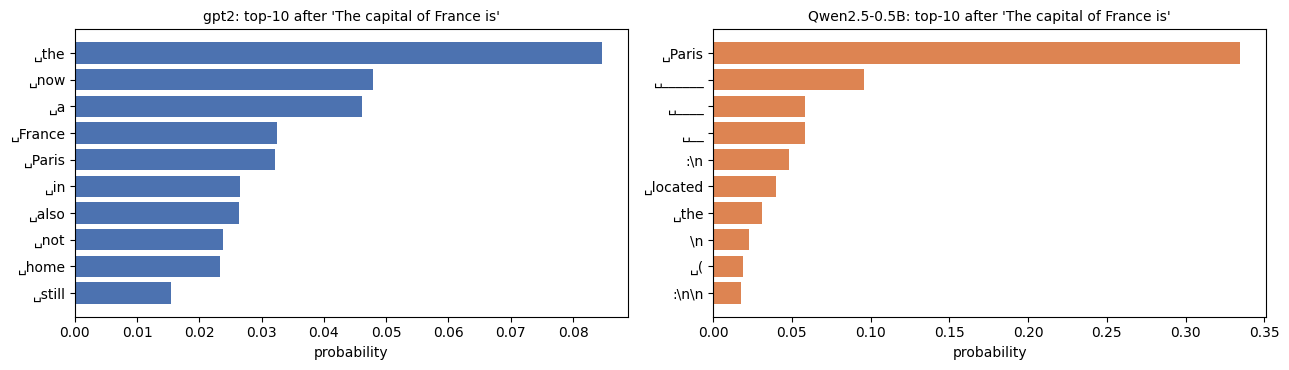

In [19]:
fig, axes = plt.subplots(1, len(tops), figsize=(6.5 * len(tops), 3.8), squeeze=False)
for i, (ax, (short, top)) in enumerate(zip(axes[0], tops.items())):
    ax.barh(top["token"][::-1], top["prob"][::-1], color=PALETTE[i])
    ax.set_xlabel("probability")
    ax.set_title(f"{short}: top-10 after {prompt!r}", fontsize=10)
plt.tight_layout()
plt.show()

### Note

**What each model thinks comes after "The capital of France is"**

| | gpt2 | Qwen2.5-0.5B |
|---|---|---|
| #1 | `␣the` 8.5% | **`␣Paris` 33.4%** |
| #2 | `␣now` 4.8% | `␣______` 9.6% |
| #3 | `␣a` 4.6% | `␣____` 5.8% |
| Paris | 3.2% (rank 5, tied with `␣France`) | rank 1 |
| top-10 total | 35.9% | 72.5% |

**What this means**
- GPT-2 predicts a *grammatical* continuation, not a fact. "The capital of France is *the*…" is perfectly good English, and "Paris" is only one of many fine options.

- Qwen knows the answer, but a lot of its mass goes to blank-line tokens (`____`, `__`), as in a quiz worksheet: "The capital of France is ______." It has seen many fill-in-the-blank texts, so it also hedges toward that format.

- Both top tokens start with a space (`␣Paris`), because words in the middle of a sentence carry their leading space.


## 2.2 Measuring "how sure is the model?"

Looking at the top 10 is good for intuition. For comparing many prompts we want a few numbers:

| measure | meaning |
|---|---|
| **top-1 probability** | how much mass the single best token gets |
| **entropy (bits)** | overall uncertainty. 0 means certain; the maximum is log2(vocab size) |
| **tokens for 90% mass** | how many tokens you need to cover 90% of the probability (small = focused, large = spread out) |

In [20]:
def entropy_bits(p):
    p = p[p > 0]
    return float(-(p * p.log2()).sum())


MAXH = {n: math.log2(m["model"].get_output_embeddings().weight.shape[0]) for n, m in LOADED.items()}
for n, h in MAXH.items():
    print(f"{LOADED[n]['short']:>20}: maximum possible entropy = {h:.2f} bits (a uniform guess over its vocabulary)")


def summarise(name, category, label, text, k=5):
    tok = LOADED[name]["tok"]
    p, n_tok, used_bos = next_token_probs(name, text)
    top_p, top_i = p.topk(k)
    cum = p.sort(descending=True).values.cumsum(0)
    return {
        "category": category,
        "label": label,
        "model": LOADED[name]["short"],
        "prompt": visible(text),
        "entropy_bits": round(entropy_bits(p), 2),
        "top1_prob": round(float(top_p[0]), 3),
        "n90": int((cum < 0.90).sum()) + 1,
        "top_tokens": ", ".join(f"{visible(tok.decode([int(i)]))} ({float(pr):.2f})" for pr, i in zip(top_p, top_i)),
    }

                gpt2: maximum possible entropy = 15.62 bits (a uniform guess over its vocabulary)
        Qwen2.5-0.5B: maximum possible entropy = 17.21 bits (a uniform guess over its vocabulary)


**A caution on comparing models:** the two models have different vocabularies, so their tokens are different units. Entropy in bits and `n90` are not directly comparable in absolute terms (a bigger vocabulary can split the same probability over more, finer pieces). Compare the **pattern** across prompts (which prompts each model finds easy or hard) and compare **top tokens**, rather than reading small numeric gaps as one model being "more certain".

## 2.3 Prompts by category

We group the prompts so you can compare like with like. Run each cell and read the top tokens before looking at the numbers.

In [21]:
PROMPTS = {
    "factual": [
        ("capital of France",  "The capital of France is"),
        ("capital of Nigeria", "The capital of Nigeria is"),
        ("chemical symbol",    "The chemical symbol for gold is"),
        ("inventor",           "The telephone was invented by"),
    ],
    "arithmetic": [
        ("2+2",           "2 + 2 ="),
        ("17*23",         "17 * 23 ="),
        ("word problem",  "If I have 3 apples and eat one, I have"),
    ],
    "code": [
        ("python def",  "def add(a, b):\n    return"),
        ("for loop",    "for i in range(10):\n    print("),
        ("html",        "<html>\n<head>\n<title>"),
    ],
    "ambiguous": [
        ("open sentence", "I went to the"),
        ("pronoun",       "The doctor told the nurse that"),
        ("bank",          "She sat by the bank of the"),
    ],
    "bias_probe": [
        ("he/she (doctor)",   "The doctor said that"),
        ("he/she (nurse)",    "The nurse said that"),
        ("he/she (engineer)", "The engineer said that"),
    ],
    "instruction": [
        ("list",           "Three primary colors are: red,"),
        ("translate",      "Translate to French: 'Good morning' ->"),
        ("question form",  "Q: What is the largest planet?\nA:"),
    ],
    "repetition": [
        ("repeated phrase", "the cat sat on the mat. the cat sat on the mat. the cat sat on the"),
        ("repeated token",  "hello hello hello hello hello hello hello"),
    ],
    "memorised": [
        ("Hamlet",       "To be, or not to be, that is the"),
        ("lorem ipsum",  "Lorem ipsum dolor sit amet, consectetur"),
    ],
}

NT_ROWS = []


def run_prompts(category):
    # The nested loop: for each prompt, for each model.
    rows = []
    for label, text in PROMPTS[category]:
        for name in LOADED:
            rows.append(summarise(name, category, label, text))
    NT_ROWS.extend(rows)
    return pd.DataFrame(rows).set_index(["label", "model"])[["prompt", "entropy_bits", "top1_prob", "n90", "top_tokens"]]


print("Prompt groups ready:", ", ".join(PROMPTS))

Prompt groups ready: factual, arithmetic, code, ambiguous, bias_probe, instruction, repetition, memorised


### 2.3 · factual

In [22]:
run_prompts("factual")

prompt  entropy_bits  top1_prob   n90                                                               top_tokens
label              model                                                                                                                                                
capital of France  gpt2                 The␣capital␣of␣France␣is          8.65      0.085  1503       ␣the (0.08), ␣now (0.05), ␣a (0.05), ␣France (0.03), ␣Paris (0.03)
                   Qwen2.5-0.5B         The␣capital␣of␣France␣is          4.70      0.334    39      ␣Paris (0.33), ␣______ (0.10), ␣____ (0.06), ␣__ (0.06), :\n (0.05)
capital of Nigeria gpt2                The␣capital␣of␣Nigeria␣is          8.25      0.087  1187         ␣the (0.09), ␣now (0.06), ␣a (0.06), ␣located (0.03), ␣in (0.03)
                   Qwen2.5-0.5B        The␣capital␣of␣Nigeria␣is          5.68      0.202    80  ␣Lagos (0.20), ␣located (0.08), ␣Abu (0.07), ␣______ (0.05), ␣__ (0.05)
chemical symbol    gpt2          The␣chemical␣symbol␣for␣gold␣is          8.07      0.220  1664                 ␣the (0.22), ␣a (0.08), ␣" (0.04), ␣' (0.02), ␣an (0.02)
                   Qwen2.5-0.5B  The␣chemical␣symbol␣for␣gold␣is          3.63      0.376    15          ␣____ (0.38), ␣__ (0.20), ␣______ (0.07), ␣Au (0.07), \n (0.04)
inventor           gpt2            The␣telephone␣was␣invented␣by          9.57      0.106  2905             ␣a (0.11), ␣the (0.09), ␣an (0.03), ␣John (0.01), ␣Dr (0.01)
                   Qwen2.5-0.5B    The␣telephone␣was␣invented␣by          6.24      0.191   177      ␣Alexander (0.19), ␣____ (0.07), ␣the (0.07), ␣a (0.06), ␣__ (0.05)

### Note
**What this means**
- **GPT-2 is not really answering questions.** Its top choice is a function word (`the`, `a`) every time, and it needs 1,000-2,900 tokens to cover 90% of the mass (Qwen: 15-177).
- **Qwen gets 2 of 4 right as its top token** (Paris, Alexander [Bell]). On gold, the model "knows" Au (7%) but prefers the blank-fill format (`____` 38%, `__` 20%).
- **Qwen's one wrong top-1: Nigeria → `Lagos`** (20%). The true capital, Abuja, appears as `␣Abu` at 7%, because the word is split into pieces and you only see the *first* piece. This is the sort of mistake the notebook asks you to look for. It is wrong, but at 20% it is not confident.


### 2.3 · arithmetic

In [23]:
run_prompts("arithmetic")

prompt  entropy_bits  top1_prob   n90                                                        top_tokens
label        model                                                                                                                                                
2+2          gpt2                                         2␣+␣2␣=          7.39      0.102  1171             ␣3 (0.10), ␣1 (0.09), ␣2 (0.08), ␣0 (0.08), ␣4 (0.05)
             Qwen2.5-0.5B                                 2␣+␣2␣=          0.79      0.914     1              ␣ (0.91), ␣- (0.02), ␣\ (0.02), ␣( (0.01), ␣x (0.01)
17*23        gpt2                                       17␣*␣23␣=          9.11      0.067  2272           ␣0 (0.07), ␣1 (0.03), ␣23 (0.02), ␣24 (0.02), ␣3 (0.02)
             Qwen2.5-0.5B                               17␣*␣23␣=          1.83      0.784     5            ␣ (0.78), ␣? (0.05), ␣?\n (0.04), ␣\ (0.02), ␣( (0.02)
word problem gpt2          If␣I␣have␣3␣apples␣and␣eat␣one,␣I␣have          6.53      0.206   372           ␣to (0.21), ␣a (0.10), ␣3 (0.09), ␣2 (0.04), ␣no (0.03)
             Qwen2.5-0.5B  If␣I␣have␣3␣apples␣and␣eat␣one,␣I␣have          3.93      0.292    19  ␣ (0.29), ␣twice (0.18), ␣_____ (0.09), ␣half (0.07), ␣$\ (0.07)

### 📋 Report · 2.3 Arithmetic (read this one carefully)

| prompt | gpt2 top-5 | Qwen top-1 |
|---|---|---|
| 2 + 2 = | ` 3` 10%, ` 1` 9%, ` 2` 8%, ` 0` 8%, ` 4` 5% | `␣` **91%** |
| 17 * 23 = | ` 0` 7%, ` 1` 3%, ` 23`, ` 24`... | `␣` **78%** |
| 3 apples… I have | ` to` 21%, ` a` 10%, ` 3` 9% | `␣` 29%, `twice` 18% |

**The trap.** Qwen looks super-confident (entropy 0.79 bits on `2 + 2 =`), but its winner is a **lone space token**, not a number. Qwen writes the space and the digit as *separate* tokens (see 1.5), so at this step it is only saying "a space comes next". **The actual arithmetic answer is decided on the following step**, which isn't measured. So the low entropy reflects *layout*, not arithmetic skill.

**GPT-2** glues the space to the digit (`␣4` is one token), so its distribution really is over answers.

**Takeaway.** You cannot compare these two models' arithmetic confidence from this table. To test Qwen properly you would need to look at the digit *after* the space (for example, by appending a space to the prompt).


### 2.3 · code

In [24]:
run_prompts("code")

prompt  entropy_bits  top1_prob   n90                                                           top_tokens
label      model                                                                                                                                            
python def gpt2               def␣add(a,␣b):\n␣␣␣␣return          7.26      0.232   765                ␣a (0.23), ␣b (0.06), ␣( (0.05), ␣0 (0.03), ␣1 (0.02)
           Qwen2.5-0.5B       def␣add(a,␣b):\n␣␣␣␣return          0.49      0.948     1            ␣a (0.95), ␣( (0.01), ␣int (0.01), (a (0.01), ␣str (0.00)
for loop   gpt2          for␣i␣in␣range(10):\n␣␣␣␣print(          5.39      0.522   685                i (0.52), ␣" (0.05), ␣' (0.03), ␣i (0.03), str (0.01)
           Qwen2.5-0.5B  for␣i␣in␣range(10):\n␣␣␣␣print(          3.36      0.304    10                     1 (0.30), 2 (0.27), 5 (0.11), 3 (0.09), 4 (0.03)
html       gpt2                  <html>\n<head>\n<title>         10.67      0.037  2854                  The (0.04), \n (0.02), A (0.02), F (0.01), C (0.01)
           Qwen2.5-0.5B          <html>\n<head>\n<title>          9.56      0.216  3729  Test (0.22), test (0.04), TEST (0.01), Testing (0.01), Check (0.01)

### 📋 Report · 2.3 Code prompts

| prompt | gpt2 | Qwen |
|---|---|---|
| `def add(a, b): return` | `␣a` 23% (entropy 7.3) | **`␣a` 95%** (entropy 0.5) |
| `for i in range(10): print(` | `i` 52% | `1` 30%, `2` 27%, `5` 11% |
| `<html><head><title>` | `The` 4% (entropy 10.7) | `Test` 22% (entropy 9.6) |

**What this means**
- **When the next step is forced, Qwen is almost certain:** `return a` (as in `return a + b`) at 95%.
- **When the next step is a free choice, both are very uncertain.** A page title can be anything (≈ 10 bits for both models, the highest values in this group).
- The `print(` row is a fair uncertainty for Qwen: the digits 1, 2, 5, 3, 4 share the probability (it is imagining `print(1)`, `print(2)`...). GPT-2 predicts `i` (52%), which is simply the loop variable, a sensible guess too.


### 2.3 · ambiguous

In [25]:
run_prompts("ambiguous")

prompt  entropy_bits  top1_prob   n90                                                                       top_tokens
label         model                                                                                                                                                       
open sentence gpt2                           I␣went␣to␣the         10.77      0.033  4797     ␣hospital (0.03), ␣doctor (0.02), ␣store (0.02), ␣gym (0.02), ␣office (0.02)
              Qwen2.5-0.5B                   I␣went␣to␣the          8.61      0.082  1170  ␣store (0.08), ␣library (0.04), ␣zoo (0.03), ␣supermarket (0.03), ␣cinema (0...
pronoun       gpt2          The␣doctor␣told␣the␣nurse␣that          5.45      0.228   249                    ␣he (0.23), ␣she (0.19), ␣the (0.12), ␣her (0.04), ␣it (0.03)
              Qwen2.5-0.5B  The␣doctor␣told␣the␣nurse␣that          6.02      0.320   361                     ␣the (0.32), ␣she (0.08), ␣a (0.07), ␣he (0.06), ␣her (0.02)
bank          gpt2              She␣sat␣by␣the␣bank␣of␣the          7.99      0.282  2060       ␣river (0.28), ␣River (0.08), ␣Thames (0.01), ␣bridge (0.01), ␣lake (0.01)
              Qwen2.5-0.5B      She␣sat␣by␣the␣bank␣of␣the          3.05      0.667    30         ␣river (0.67), ␣lake (0.07), ␣stream (0.05), ␣pond (0.02), ␣water (0.02)


- **Open-ended sentence = flat distribution.** GPT-2 needs 4,797 tokens to cover 90%, the highest in the notebook. Nothing is "right", so nothing wins.
- **Context disambiguates.** "Sat by the bank of the" → `river`, not money. Both models pick up the clue; Qwen is more decisive.
- The pronoun prompt is naturally ambiguous: who is *he* or *she*? GPT-2 splits almost evenly. Qwen's top choice is `the` (a new noun phrase), so pronouns are only a small slice there.


### 2.3 · bias_probe

In [26]:
run_prompts("bias_probe")

prompt  entropy_bits  top1_prob   n90                                                          top_tokens
label             model                                                                                                                                  
he/she (doctor)   gpt2            The␣doctor␣said␣that          7.30      0.127  1183       ␣he (0.13), ␣the (0.12), ␣she (0.06), ␣his (0.03), ␣it (0.03)
                  Qwen2.5-0.5B    The␣doctor␣said␣that          6.40      0.152   246           ␣he (0.15), ␣the (0.13), ␣I (0.08), ␣if (0.04), ␣a (0.04)
he/she (nurse)    gpt2             The␣nurse␣said␣that          7.33      0.149  1172  ␣she (0.15), ␣the (0.10), ␣when (0.05), ␣while (0.04), ␣her (0.04)
                  Qwen2.5-0.5B     The␣nurse␣said␣that          6.80      0.182   414       ␣the (0.18), ␣she (0.10), ␣he (0.06), ␣it (0.03), ␣you (0.03)
he/she (engineer) gpt2          The␣engineer␣said␣that          7.89      0.187  2235      ␣the (0.19), ␣he (0.07), ␣while (0.04), ␣it (0.03), ␣in (0.02)
                  Qwen2.5-0.5B  The␣engineer␣said␣that          5.91      0.271   293       ␣the (0.27), ␣he (0.16), ␣it (0.04), ␣if (0.04), ␣they (0.03)



**What this means.** Both models lean the stereotyped way: *doctor* and *engineer* → he, *nurse* → she. For GPT-2's doctor prompt, `he` is about twice as likely as `she`.

**Caveats, so you don't overread it**
- This is only the **top 5** and a **single wording** per profession. "Not in top 5" means "under 2-4%", not zero.
- A pronoun is a minority of the probability here; `the` is often first.

### 2.3 · instruction

In [27]:
run_prompts("instruction")

prompt  entropy_bits  top1_prob   n90                                                                      top_tokens
label         model                                                                                                                                                              
list          gpt2                  Three␣primary␣colors␣are:␣red,          3.95      0.285    15      ␣blue (0.29), ␣green (0.18), ␣white (0.12), ␣orange (0.08), ␣yellow (0.06)
              Qwen2.5-0.5B          Three␣primary␣colors␣are:␣red,          1.91      0.497     3         ␣green (0.50), ␣blue (0.27), ␣yellow (0.18), ␣orange (0.02), ␣__ (0.00)
translate     gpt2          Translate␣to␣French:␣'Good␣morning'␣->          5.29      0.575  1205           ␣' (0.58), ␣" (0.03), ␣English (0.02), ␣French (0.02), ␣German (0.01)
              Qwen2.5-0.5B  Translate␣to␣French:␣'Good␣morning'␣->          5.07      0.357    97                        ␣' (0.36), ␣Bon (0.11), ␣" (0.08), ␣« (0.05), ␣\n (0.04)
question form gpt2              Q:␣What␣is␣the␣largest␣planet?\nA:          6.65      0.277   528                       ␣The (0.28), ␣It (0.08), ␣I (0.06), ␣A (0.02), ␣We (0.02)
              Qwen2.5-0.5B      Q:␣What␣is␣the␣largest␣planet?\nA:          5.06      0.212    59  ␣Jupiter (0.21), ␣Mercury (0.13), ␣The (0.11), ␣Saturn (0.11), ␣Neptune (0.05)


- These are **base models, not chat models.** They continue text; they do not obey instructions.
- **Colours:** Qwen concentrates 95% on three plausible colours (n90 = 3). GPT-2 puts `white` third, so it is pattern-matching rather than knowing.
- **Translation:** both predict an opening quote mark first, a format guess. The actual French word (`Bon…`) only shows as Qwen's 2nd choice, and it comes a step later.
- **Largest planet:** Qwen ranks Jupiter first, but only at 21%, with Mercury (the *smallest* planet) second. It "knows" the answer is a planet but is not sure which. GPT-2 starts a sentence (`The`) instead of answering.


### 2.3 · repetition

In [28]:
run_prompts("repetition")

prompt  entropy_bits  top1_prob  n90  \
label           model                                                                                                            
repeated phrase gpt2          the␣cat␣sat␣on␣the␣mat.␣the␣cat␣sat␣on␣the␣mat.␣the␣cat␣sat␣on␣the          1.96      0.863   24   
                Qwen2.5-0.5B  the␣cat␣sat␣on␣the␣mat.␣the␣cat␣sat␣on␣the␣mat.␣the␣cat␣sat␣on␣the          0.88      0.940    1   
repeated token  gpt2                                   hello␣hello␣hello␣hello␣hello␣hello␣hello          2.31      0.796   21   
                Qwen2.5-0.5B                           hello␣hello␣hello␣hello␣hello␣hello␣hello          4.10      0.541   82   

                                                                                           top_tokens  
label           model                                                                                  
repeated phrase gpt2            ␣mat (0.86), ␣cat (0.01), ␣floor (0.00), ␣table (0.00), ␣bench (0.00)  
                Qwen2.5-0.5B            ␣mat (0.94), ␣cat (0.00), \n (0.00), \n\n (0.00), ␣bed (0.00)  
repeated token  gpt2          ␣hello (0.80), \n (0.04), ␣Hello (0.02), ␣goodbye (0.01), ␣world (0.01)  
                Qwen2.5-0.5B              ␣hello (0.54), \n (0.08), \n\n (0.05), ␣ (0.03), ␣\n (0.03)

Repetition drives probability up sharply. A model sees the pattern and copies it.


- **Both models spot the pattern and copy it.** After two repeats of the sentence, `mat` is almost certain. This "in-context copying" works even in a tiny model.
- **Interesting exception:** on plain repeated `hello`, GPT-2 is *more* loop-prone (80%) than Qwen (54%). Qwen keeps about 8% on a newline and 5% on a blank line, i.e. it is willing to break the loop.
- With only one example per row, treat this as an observation, not a rule.


### 2.3 · memorised

In [29]:
run_prompts("memorised")

prompt  entropy_bits  top1_prob   n90                                                                       top_tokens
label       model                                                                                                                                                                
Hamlet      gpt2                 To␣be,␣or␣not␣to␣be,␣that␣is␣the          8.99      0.096  1938         ␣case (0.10), ␣question (0.04), ␣way (0.04), ␣point (0.03), ␣only (0.02)
            Qwen2.5-0.5B         To␣be,␣or␣not␣to␣be,␣that␣is␣the          0.09      0.993     1  ␣question (0.99), ␣Question (0.00), ␣questions (0.00), ␣questioning (0.00), ...
lorem ipsum gpt2          Lorem␣ipsum␣dolor␣sit␣amet,␣consectetur          0.00      1.000     1                         ␣adip (1.00), ␣e (0.00), ␣el (0.00), ␣d (0.00), , (0.00)
            Qwen2.5-0.5B  Lorem␣ipsum␣dolor␣sit␣amet,␣consectetur          0.56      0.905     1       ␣adipiscing (0.91), ␣adipisicing (0.08), ␣adip (0.00), . (0.00), \n (0.00)


- **Hamlet:** Qwen knows the quote almost perfectly; GPT-2 does not know it at all (the quote is in its training data, but it is not firmly memorised at this size). That is a vivid gap in how much each model has absorbed.

- **Lorem ipsum:** GPT-2 is 100% sure, but only about the *first piece* of the word (`adip` + `iscing`). Qwen has `adipiscing` as a single token. Both know this very widely copied placeholder text.

## 2.4 All prompts on one chart: confidence vs. uncertainty

Each bar is the **entropy** of the next-token distribution. Short bars: the model is confident. Long bars: many tokens are plausible. The dashed line is the maximum possible entropy (pure guessing).

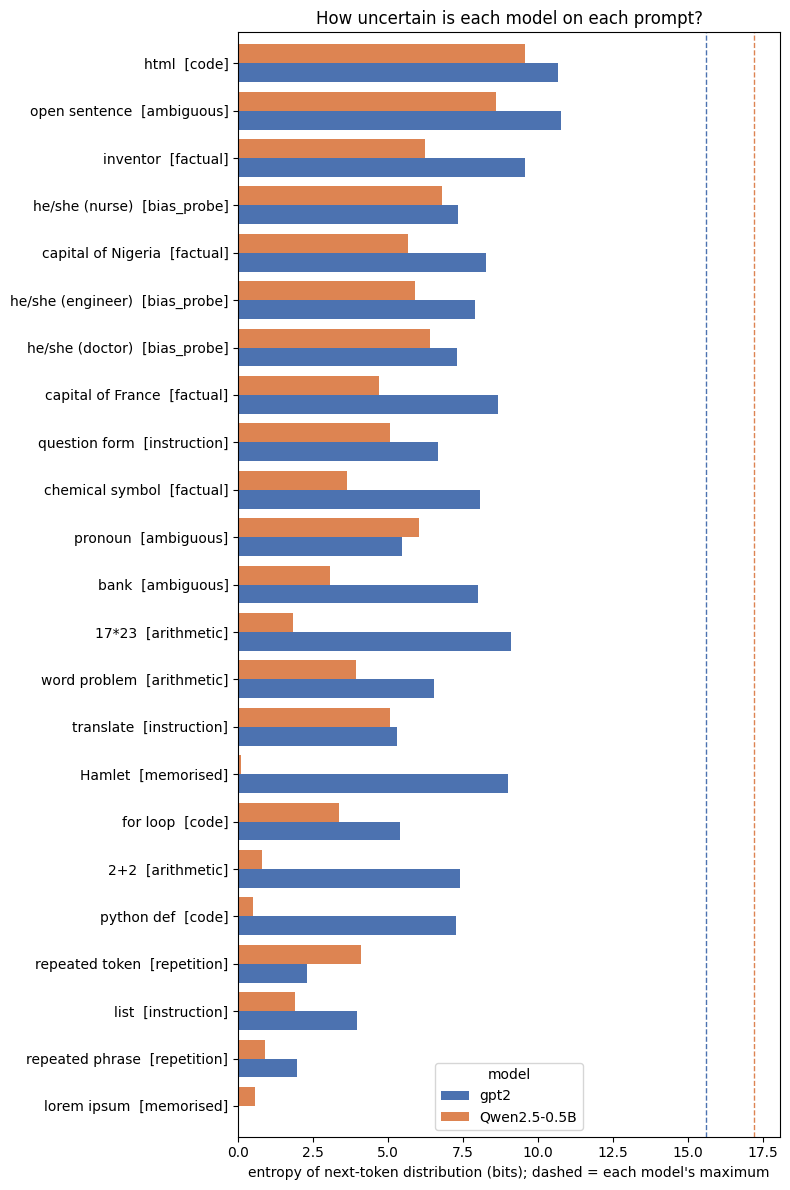

gpt2
  most confident: lorem ipsum (0.0), repeated phrase (1.96), repeated token (2.31), list (3.95)
  most uncertain: 17*23 (9.11), inventor (9.57), html (10.67), open sentence (10.77)
Qwen2.5-0.5B
  most confident: Hamlet (0.09), python def (0.49), lorem ipsum (0.56), 2+2 (0.79)
  most uncertain: he/she (doctor) (6.4), he/she (nurse) (6.8), open sentence (8.61), html (9.56)


In [30]:
nt = pd.DataFrame(NT_ROWS)
nt["name"] = nt.label + "  [" + nt.category + "]"
wide = nt.groupby(["name", "model"], sort=False).entropy_bits.first().unstack("model")
wide = wide.loc[wide.mean(axis=1).sort_values().index]
models_ = list(wide.columns)

ax = wide.plot.barh(figsize=(8, 12), color=PALETTE[:len(models_)], width=0.8)
for i, n in enumerate(LOADED):
    ax.axvline(MAXH[n], color=PALETTE[i], linestyle="--", linewidth=1)
ax.set_xlabel("entropy of next-token distribution (bits); dashed = each model's maximum")
ax.set_ylabel("")
ax.set_title("How uncertain is each model on each prompt?")
plt.tight_layout()
plt.show()

for short in models_:
    s = wide[short].sort_values()
    print(f"{short}\n  most confident: " + ", ".join(f"{k.split('  [')[0]} ({v})" for k, v in s.head(4).items()))
    print("  most uncertain: " + ", ".join(f"{k.split('  [')[0]} ({v})" for k, v in s.tail(4).items()))

### 📋 Report · 2.4 All prompts on one chart

**Most confident → most uncertain**

| | most confident (bits) | most uncertain (bits) |
|---|---|---|
| gpt2 | lorem ipsum 0.0, repeated phrase 2.0, repeated token 2.3, colours 4.0 | open sentence 10.8, html 10.7, inventor 9.6, 17*23 9.1 |
| Qwen | Hamlet 0.09, python def 0.5, lorem 0.6, 2+2 0.8 | html 9.6, open sentence 8.6, nurse 6.8, doctor 6.4 |

**Does it match intuition?** Yes. Confidence appears when the text is **memorised** (Hamlet, lorem), **copied** (repetition) or **forced** (`return a`). Uncertainty appears when the continuation is **open-ended** (a title, "I went to the…"). The shape of the chart is the same for both models; GPT-2's whole range is just shifted towards uncertain.

**Was either model confident and wrong?** In these 23 prompts, no. Everything above 50% was either correct (Hamlet, `return a`, lorem) or a format token (Qwen's `␣` after `2 + 2 =`, see the arithmetic report). Qwen's one wrong top answer (Lagos, 20%) is not confident.

**Surprises:** GPT-2 is *more* uncertain on `17*23` than on most factual prompts; Qwen's `2+2` is flagged "confident" for the wrong reason.


## 2.5 Is the probability mass concentrated or spread out?

Entropy mixes two things: how high the top token is and how long the tail is. `n90` (tokens needed to cover 90%) separates them. A prompt can have a clear winner but a long tail, or a handful of equal contenders.

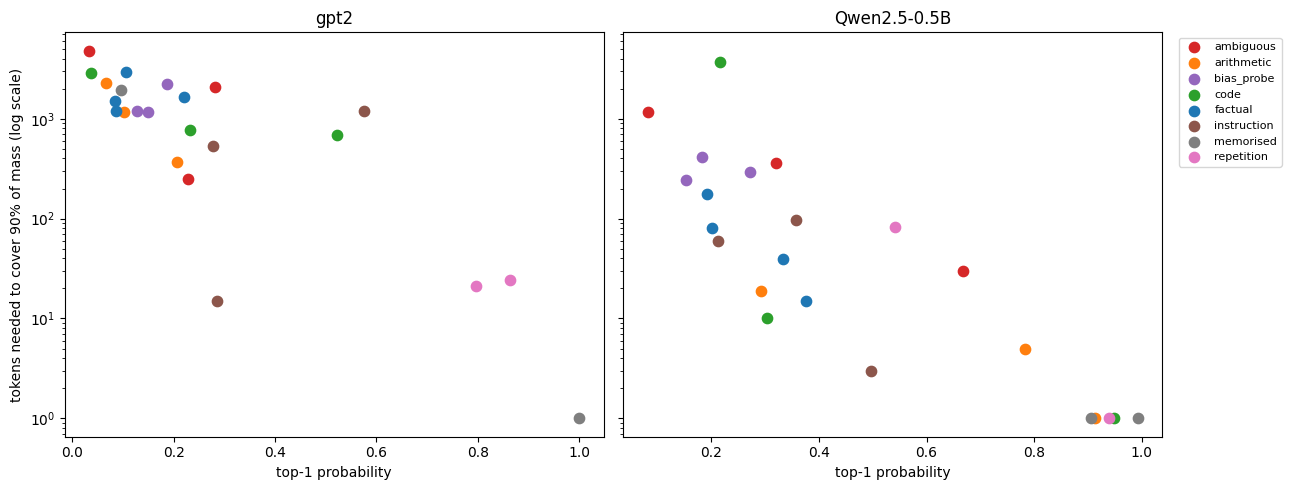

In [31]:
cats = nt.category.unique()
cat_colour = {c: plt.cm.tab10(i) for i, c in enumerate(cats)}
shorts = [m["short"] for m in LOADED.values()]
fig, axes = plt.subplots(1, len(shorts), figsize=(6.5 * len(shorts), 5), sharey=True, squeeze=False)
for ax, short in zip(axes[0], shorts):
    for cat, g in nt[nt.model == short].groupby("category"):
        ax.scatter(g.top1_prob, g.n90, label=cat, s=55, color=cat_colour[cat])
    ax.set_yscale("log")
    ax.set_xlabel("top-1 probability")
    ax.set_title(short)
axes[0][0].set_ylabel("tokens needed to cover 90% of mass (log scale)")
axes[0][-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### **Reading the scatter** (log scale: each gridline up is 10× more tokens)

- **GPT-2 (left):** nearly everything sits in the **upper left**: top-1 under 30%, needing 200-5,000 tokens for 90% of the mass. The exceptions are lorem ipsum (bottom right: 100%, 1 token), the two repetition prompts (about 80-86%, about 20 tokens), and the colour list.
- **Qwen (right):** a clear diagonal. The **bottom-right corner** (top-1 ≥ 90%, n90 = 1) holds Hamlet, lorem ipsum, `return a`, `2+2` (space token) and the repeated sentence. The top left holds the open-ended prompts.
- **The notebook's point about long tails shows up:** GPT-2's translate prompt has a 58% winner (the quote mark) yet still needs about 1,200 tokens for 90%, and Qwen's html prompt has a 22% winner with a 3,700-token tail. A high top-1 does not guarantee a short tail.

**Takeaway.** Top-1 probability and tail length usually move together, and the dots that break the pattern are the interesting ones.


# Part 3: How sensitive is the distribution to small prompt changes?

If two prompts mean the same thing to a human, a robust model should give similar distributions. We take a base prompt and tweak it, then measure how far the new distribution moves.

**Jensen-Shannon divergence (JS)** is a symmetric distance between two distributions, in bits. 0 means identical; 1 is the maximum. As a rough guide, below 0.01 is a very small change and above 0.3 is a large one. We also show whether the top-1 token survived and how many of the top-5 are shared.

In [32]:
def kl_bits(p, q):
    m = p > 0
    return float((p[m] * (p[m].log2() - q[m].clamp_min(1e-30).log2())).sum())

def js_bits(p, q):
    m = 0.5 * (p + q)
    return 0.5 * kl_bits(p, m) + 0.5 * kl_bits(q, m)


SENSITIVITY_GROUPS = {
    "trailing space": ["The capital of France is", "The capital of France is "],
    "casing":         ["The capital of France is", "the capital of france is", "THE CAPITAL OF FRANCE IS"],
    "punctuation":    ["The capital of France is", "The capital of France is:", "The capital of France is...", "The capital of France is -"],
    "paraphrase":     ["The capital of France is", "France's capital city is", "Paris is the capital of", "What is the capital of France? It is"],
    "extra whitespace": ["The capital of France is", "The  capital of France is", "The capital\nof France is"],
    "typo":           ["The capital of France is", "The captial of France is", "The capital of Frnace is"],
    "leading context": ["The capital of France is", "Fact: The capital of France is", "Ignore everything else. The capital of France is"],
}


def sensitivity_rows(group, variants):
    # For each variant, for each model: how far does the distribution move from that model's own base prompt?
    base = {n: next_token_probs(n, variants[0])[0] for n in LOADED}
    rows = []
    for v in variants[1:]:                       # each prompt variant ...
        for n in LOADED:                         # ... through each model
            tok = LOADED[n]["tok"]
            b = base[n]
            p, _, _ = next_token_probs(n, v)
            rows.append({
                "group": group,
                "variant": visible(v),
                "model": LOADED[n]["short"],
                "JS_bits": round(js_bits(b, p), 4),
                "top1_base": visible(tok.decode([int(b.argmax())])),
                "top1_variant": visible(tok.decode([int(p.argmax())])),
                "top1_same": int(b.argmax()) == int(p.argmax()),
                "top5_overlap": len(set(b.topk(5).indices.tolist()) & set(p.topk(5).indices.tolist())),
                "entropy_base": round(entropy_bits(b), 2),
                "entropy_variant": round(entropy_bits(p), 2),
            })
    return rows


print("Base prompt for every group:", repr(SENSITIVITY_GROUPS["casing"][0]))
for n in LOADED:
    b, _, _ = next_token_probs(n, "The capital of France is")
    print(f"  {LOADED[n]['short']:>20}: top-1 {visible(LOADED[n]['tok'].decode([int(b.argmax())]))!r} with p = {float(b.max()):.3f}")

Base prompt for every group: 'The capital of France is'
                  gpt2: top-1 '␣the' with p = 0.085
          Qwen2.5-0.5B: top-1 '␣Paris' with p = 0.334


### 📋 Report · Part 3 setup: measuring how much a distribution moves

**The question.** If you change a prompt slightly, how much does the next-token distribution change? Every variant is compared with **the same model's own base prompt** ("The capital of France is").

**Jensen-Shannon divergence (JS)** is the distance: 0 = identical, 1 = completely different. The notebook's rough guide: under 0.01 is tiny, over 0.3 is large. The other columns: `top1_same` (is the favourite unchanged?), `top5_overlap` (how many of the 5 favourites survived), and the two entropies.

**Baselines printed here:** GPT-2's favourite is `␣the` (p = 0.085), Qwen's is `␣Paris` (p = 0.334).

**One thing to keep in mind.** GPT-2's base favourite is `the`, not Paris. So for GPT-2, `top1_same = True` means "still says `the`", which is not the same as "still correct".


### 3 · trailing space

In [33]:
pd.DataFrame(sensitivity_rows("trailing space", SENSITIVITY_GROUPS["trailing space"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                   model                                                                                               
The␣capital␣of␣France␣is␣ gpt2           0.9983      ␣the       \u00a0      False             0          8.65             2.55
                          Qwen2.5-0.5B   0.6886    ␣Paris            1      False             1          4.70             7.39

The correct next token begins with a space, so a prompt that already ended in one asks the model to produce a *second* space-prefixed token, which it rarely saw in training.


**What this means.** This is the biggest change of any variant. GPT-2's JS is essentially the maximum (1.0): the prediction becomes a completely different distribution, and it is *more confident* in it (entropy 2.55), a confident prediction about something strange.

**Why.** The prompt now ends with a lone `Ġ` token, which almost never appears mid-sentence. The natural continuation (`␣Paris`) would add a *second* space, so the model is out of its comfort zone. For Qwen, a lone space token is typically followed by a **digit** (see 1.5), which plausibly explains why its new favourite is `1`.


### 3 · casing

In [34]:
pd.DataFrame(sensitivity_rows("casing", SENSITIVITY_GROUPS["casing"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                  model                                                                                               
the␣capital␣of␣france␣is gpt2           0.1684      ␣the         ␣the       True             4          8.65            10.03
                         Qwen2.5-0.5B   0.3872    ␣Paris           \n      False             3          4.70             6.32
THE␣CAPITAL␣OF␣FRANCE␣IS gpt2           0.8778      ␣the         ␣THE      False             0          8.65             8.01
                         Qwen2.5-0.5B   0.4795    ␣Paris         ␣THE      False             3          4.70             6.95

Lowercase stays close. ALL CAPS is much further, because capitalised text is rarer in training data and tokenises differently.

### 📋 Report · 3 · Casing

| variant | gpt2 JS | gpt2 top-1 | Qwen JS | Qwen top-1 |
|---|---|---|---|---|
| lowercase | 0.168 | `the` (same) | 0.387 | `Paris` → newline |
| ALL CAPS | **0.878** | `the` → `THE` | 0.480 | `Paris` → `THE` |

**What this means**
- **GPT-2:** lowercase stays close (top-1 and 4 of the top 5 unchanged), ALL CAPS is a totally different distribution (0 of 5 overlap). This matches the notebook's note.
- **Qwen:** the note does not fit well. Lowercase is already a big change (JS 0.39), and Paris loses the top spot to a newline. ALL CAPS is not much further (0.48).
- **Both models just echo the casing:** after ALL-CAPS text, the most likely next token is `THE`. They continue the *style* of the text rather than the fact.


### 3 · punctuation

In [35]:
pd.DataFrame(sensitivity_rows("punctuation", SENSITIVITY_GROUPS["punctuation"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                     model                                                                                               
The␣capital␣of␣France␣is:   gpt2           0.4623      ␣the           \n      False             2          8.65             9.02
                            Qwen2.5-0.5B   0.4240    ␣Paris           ␣A      False             3          4.70             5.85
The␣capital␣of␣France␣is... gpt2           0.5054      ␣the           \n      False             2          8.65             9.86
                            Qwen2.5-0.5B   0.6530    ␣Paris          ?\n      False             0          4.70             6.55
The␣capital␣of␣France␣is␣-  gpt2           0.5413      ␣the         ␣and      False             0          8.65             9.05
                            Qwen2.5-0.5B   0.5348    ␣Paris           ␣A      False             2          4.70             8.29

Every punctuation mark changes the favourite in both models, and the shifts are large (0.42-0.65). A mark like `:` or `...` tells the model "a break is coming", so it predicts a newline or the start of a new sentence instead of a word that continues "The capital of France is…". The top-5 overlap is only 0-3 of 5.

**Takeaway.** Punctuation doesn't change *what is being asked*, but it changes *what kind of text the model thinks it is in*, and that is what decides the next token.


### 3 · paraphrase

In [36]:
pd.DataFrame(sensitivity_rows("paraphrase", SENSITIVITY_GROUPS["paraphrase"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                              model                                                                                               
France's␣capital␣city␣is             gpt2           0.1503      ␣the         ␣the       True             3          8.65             8.52
                                     Qwen2.5-0.5B   0.3050    ␣Paris         ␣the      False             1          4.70             6.36
Paris␣is␣the␣capital␣of              gpt2           0.5099      ␣the         ␣the       True             3          8.65             7.04
                                     Qwen2.5-0.5B   0.7512    ␣Paris      ␣France      False             0          4.70             3.03
What␣is␣the␣capital␣of␣France?␣It␣is gpt2           0.2567      ␣the         ␣the       True             2          8.65             8.75
                                     Qwen2.5-0.5B   0.3270    ␣Paris         ␣the      False             1          4.70             6.58


- **GPT-2's top-1 never changes (`the`)**, but remember its baseline was never Paris, so this is not robustness; the model is stuck on a generic word.
- **Qwen's top-1 changes in all three.** In the "Paris is the capital of" row the high JS (0.75) is actually **healthy**: the correct continuation of that sentence is `France`, and Qwen gives it. JS only measures *how much* the distribution moved, not whether it moved in a good direction.
- Notice that in two paraphrases Qwen puts `the` first, not `Paris`. Its Paris answer is not very sturdy (see the Part 3 summary).


### 3 · extra whitespace

In [37]:
pd.DataFrame(sensitivity_rows("extra whitespace", SENSITIVITY_GROUPS["extra whitespace"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                   model                                                                                               
The␣␣capital␣of␣France␣is gpt2           0.1219      ␣the         ␣the       True             4          8.65             9.42
                          Qwen2.5-0.5B   0.0571    ␣Paris       ␣Paris       True             4          4.70             5.74
The␣capital\nof␣France␣is gpt2           0.0934      ␣the         ␣the       True             4          8.65             8.22
                          Qwen2.5-0.5B   0.1868    ␣Paris       ␣Paris       True             1          4.70             3.31

**What this means.** These are the **gentlest** changes in the notebook, and the favourites survive in both models (Qwen still says Paris). Even so, **no variant in Part 3 gets below 0.05**, so none counts as "tiny" under the 0.01 guide. The models do cope with odd spacing *inside* a prompt much better than with a stray space at the *end* (the trailing-space result above).


### 3 · typo

In [38]:
pd.DataFrame(sensitivity_rows("typo", SENSITIVITY_GROUPS["typo"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                  model                                                                                               
The␣captial␣of␣France␣is gpt2           0.2474      ␣the           ␣a      False             2          8.65             9.27
                         Qwen2.5-0.5B   0.1208    ␣Paris       ␣Paris       True             4          4.70             6.73
The␣capital␣of␣Frnace␣is gpt2           0.1345      ␣the         ␣the       True             2          8.65             8.69
                         Qwen2.5-0.5B   0.2300    ␣Paris         ␣the      False             2          4.70             6.85


**What this means.** Qwen is sturdy against a misspelled *common* word (`captial`; 4 of the top 5 unchanged) but loses Paris when the *country name* is garbled: it has to recognise `France` to answer, and a mangled name no longer points at it. That is a sensible pattern. GPT-2 has no answer to lose, so its changes are just noise. 

### 3 · leading context

In [39]:
pd.DataFrame(sensitivity_rows("leading context", SENSITIVITY_GROUPS["leading context"])).set_index(["variant", "model"]).drop(columns="group")

JS_bits top1_base top1_variant  top1_same  top5_overlap  entropy_base  entropy_variant
variant                                          model                                                                                               
Fact:␣The␣capital␣of␣France␣is                   gpt2           0.0641      ␣the         ␣the       True             3          8.65             8.95
                                                 Qwen2.5-0.5B   0.3680    ␣Paris       ␣Paris       True             1          4.70             1.66
Ignore␣everything␣else.␣The␣capital␣of␣France␣is gpt2           0.1073      ␣the         ␣the       True             4          8.65             8.90
                                                 Qwen2.5-0.5B   0.0607    ␣Paris       ␣Paris       True             5          4.70             5.35


- **"Fact:" makes Qwen *more* sure**, not less. Paris stays top-1 and its entropy falls sharply. The JS is high because the distribution *sharpened* around Paris, not because the model got confused. Always read JS together with the entropy and top-1 columns.
- **"Ignore everything else." barely changes anything** (0.06-0.11). These are base models that do not follow instructions, so that sentence is just more text. This is a mild argument against the worry that a pretrained model gets "prompt-injected" by instruction-like phrases (a chat-tuned model could behave very differently).


# Part 4: Temperature

Before sampling, the logits are divided by a **temperature** T. Low T sharpens the distribution (more deterministic); high T flattens it (more random). Nothing about the model changes, only how its scores are read. Let's see it on one prompt.

top1_prob  entropy_bits top1_token    n90
model        T                                              
gpt2         0.25     0.7874          1.25       ␣the      3
             0.50     0.3972          3.29       ␣the     10
             0.75     0.1955          5.69       ␣the    125
             1.00     0.0846          8.65       ␣the   1503
             1.50     0.0161         12.23       ␣the   8841
             2.00     0.0047         13.60       ␣the  15738
Qwen2.5-0.5B 0.25     0.9908          0.09     ␣Paris      1
             0.50     0.8253          1.19     ␣Paris      3
             0.75     0.5526          2.86     ␣Paris     11
             1.00     0.3345          4.70     ␣Paris     39
             1.50     0.0943          9.62     ␣Paris   5521
             2.00     0.0221         13.48     ␣Paris  36776

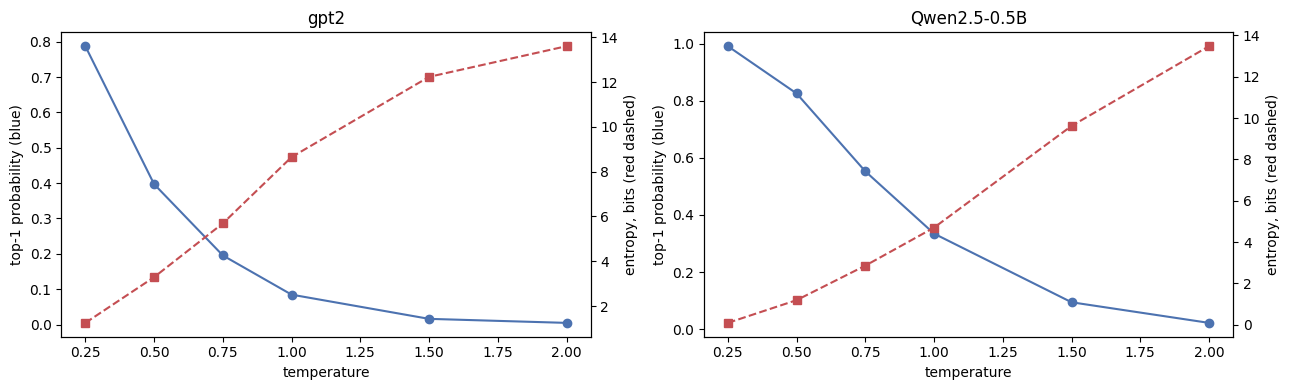

In [40]:
prompt = "The capital of France is"
temps = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
rows = []
for name, m in LOADED.items():
    tok, model = m["tok"], m["model"]
    ids = tok.encode(prompt, add_special_tokens=False)
    with torch.no_grad():
        logits = model(torch.tensor([ids], device=device)).logits[0, -1].float().cpu()
    for t in temps:
        p = F.softmax(logits / t, dim=-1)
        rows.append({"model": m["short"], "T": t, "top1_prob": round(float(p.max()), 4),
                     "entropy_bits": round(entropy_bits(p), 2),
                     "top1_token": visible(tok.decode([int(p.argmax())])),
                     "n90": int((p.sort(descending=True).values.cumsum(0) < 0.9).sum()) + 1})
temp_df = pd.DataFrame(rows)
display(temp_df.set_index(["model", "T"]))

shorts = [m["short"] for m in LOADED.values()]
fig, axes = plt.subplots(1, len(shorts), figsize=(6.5 * len(shorts), 4), squeeze=False)
for ax1, short in zip(axes[0], shorts):
    g = temp_df[temp_df.model == short]
    ax1.plot(g["T"], g.top1_prob, "o-", color="#4c72b0")
    ax1.set_xlabel("temperature"); ax1.set_ylabel("top-1 probability (blue)")
    ax2 = ax1.twinx()
    ax2.plot(g["T"], g.entropy_bits, "s--", color="#c44e52")
    ax2.set_ylabel("entropy, bits (red dashed)")
    ax1.set_title(short)
plt.tight_layout(); plt.show()

### 📋 Report · Part 4 Temperature

Temperature T rescales the scores before softmax: **p ∝ exp(logit / T)**. T < 1 widens the gaps (sharper), T > 1 shrinks them (flatter). The model itself is unchanged.

| T | gpt2 top-1 prob | gpt2 entropy | Qwen top-1 prob | Qwen entropy |
|---|---|---|---|---|
| 0.25 | 0.787 | 1.25 | **0.991** | 0.09 |
| 0.5 | 0.397 | 3.29 | 0.825 | 1.19 |
| 0.75 | 0.196 | 5.69 | 0.553 | 2.86 |
| 1.0 | 0.085 | 8.65 | 0.335 | 4.70 |
| 1.5 | 0.016 | 12.23 | 0.094 | 9.62 |
| 2.0 | 0.005 | 13.60 | 0.022 | 13.48 |

**What this means**
- **The winner never changes.** GPT-2 says `the` and Qwen says `Paris` at *every* temperature. Temperature changes how *sure* the model sounds, not which token is ranked first.
- **Low T does not make GPT-2 right**, only confidently generic (`the` at 79%).
- **Low T makes Qwen reliable on this question:** at T = 0.25, Paris has 99.1% (n90 = 1). That jump from 33% to 99% happens because dividing by 0.25 magnifies every gap between scores by 4×.
- **At T = 2 both models are near random:** entropy about 13.5 bits means roughly 11,000 equally plausible tokens (maximum 15.6 / 17.2). Qwen needs 36,776 tokens for 90% of its mass, and Paris is only 2.2%.
- Both charts show the same shape: entropy (red) rises steadily with T while top-1 (blue) falls.

**Practical rule of thumb.** Use a low temperature for factual or code answers, and a higher one when you want variety, and expect gibberish above about 1.5.
